In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import warnings
import os, glob
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

from IPython.display import display

/kaggle/input/competitions/molecular-machine-learning/sample_submission.csv
/kaggle/input/competitions/molecular-machine-learning/train.csv
/kaggle/input/competitions/molecular-machine-learning/test.csv


Section 1 : Load and inspect the data

Read the competition's training and test files. Check the number of rows and columns, column names, missing values, and the distribution of T80.

Output: a clear understanding of what the dataset contains.

In [16]:
train = pd.read_csv(glob.glob("/kaggle/input/**/train.csv", recursive=True)[0])
test  = pd.read_csv(glob.glob("/kaggle/input/**/test.csv",  recursive=True)[0])


print("Train shape", train.shape)
print("Test shape", test.shape)
print(list(train.columns))

# Columns that are in train but not in test (should be just T80)
print("Only in train:", set(train.columns) - set(test.columns))

print("\nFirst five training rows:")
display(train.head())

print("\nMissing values in training data:")
display(train.isnull().sum().sort_values(ascending=False).head(20))

Train shape (42, 146)
Test shape (9, 146)
['Batch_ID', 'T80', 'Smiles', 'Mass', 'HAcceptors', 'HDonors', 'LogP', 'Asphericity', 'Rg', 'TPSA', 'RingCount', 'NumRotatableBonds', 'NumHeteroatoms', 'HOMOm1(eV)', 'HOMO(eV)', 'LUMO(eV)', 'LUMOp1(eV)', 'PrimeState', 'PrimeExcite(eV)', 'PrimeExcite(osc)', 'DipoleMoment(Debye)', 'SurfaceCharge', 'ChargeCorrection', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15', 'T16', 'T17', 'T18', 'T19', 'T20', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'S19', 'S20', 'O1', 'O2', 'O3', 'O4', 'O5', 'O6', 'O7', 'O8', 'O9', 'O10', 'O11', 'O12', 'O13', 'O14', 'O15', 'O16', 'O17', 'O18', 'O19', 'O20', 'TDOS1.5', 'TDOS1.6', 'TDOS1.7', 'TDOS1.8', 'TDOS1.9', 'TDOS2.0', 'TDOS2.1', 'TDOS2.2', 'TDOS2.3', 'TDOS2.4', 'TDOS2.5', 'TDOS2.6', 'TDOS2.7', 'TDOS2.8', 'TDOS2.9', 'TDOS3.0', 'TDOS3.1', 'TDOS3.2', 'TDOS3.3', 'TDOS3.4', 'TDOS3.5', 'TDOS3.6', 'TDOS3

,Batch_ID,T80,Smiles,Mass,HAcceptors,HDonors,LogP,Asphericity,Rg,TPSA,...,SDOS4.5,SDOS4.6,SDOS4.7,SDOS4.8,SDOS4.9,SDOS5.0,SDOS5.1,SDOS5.2,SDOS5.3,SDOS5.4
0,Train-01,103.86,CCCCCCCCCCCCc1ccsc1-c1ccc(-c2cccs2)cc1,410.692,2,0,9.6070,0.301361,5.187321,0.00,...,1.717761,1.970186,1.760071,1.224983,0.664733,0.282353,0.096763,0.034589,0.030793,0.057340
1,Train-02,101.13,CCCCCCCCCCCCc1ccsc1-c1cccs1,334.594,2,0,7.9400,0.367472,4.141425,0.00,...,0.012396,0.046031,0.133124,0.299840,0.525958,0.718549,0.764711,0.634854,0.414866,0.225909
2,Train-03,78.30,CN1CCN(S(=O)(=O)c2ccc(-c3ccc(-c4cccs4)cc3)cc2)CC1,398.553,4,0,4.0182,0.799589,5.368024,40.62,...,2.421162,2.703267,2.352276,1.595867,0.845839,0.354620,0.127878,0.060600,0.064782,0.098908
3,Train-04,71.88,O=C1c2ccccc2C(=O)c2cc(-c3ccc(-c4cccs4)s3)ccc21,372.470,4,0,5.9190,0.793825,4.948903,34.14,...,0.886320,0.579059,0.345148,0.246564,0.276259,0.381997,0.495304,0.566935,0.594203,0.614075
4,Train-05,68.37,CC(C)(C)OC(=O)n1ccc2ccc(-c3ccc(-c4ccc(-c5cccs5...,457.620,5,0,8.5485,0.671148,5.994751,31.23,...,0.487723,0.245764,0.249019,0.363222,0.474953,0.505358,0.440671,0.330129,0.234649,0.183111



Missing values in training data:


Batch_ID             0
T80                  0
Smiles               0
Mass                 0
HAcceptors           0
HDonors              0
LogP                 0
Asphericity          0
Rg                   0
TPSA                 0
RingCount            0
NumRotatableBonds    0
NumHeteroatoms       0
HOMOm1(eV)           0
HOMO(eV)             0
LUMO(eV)             0
LUMOp1(eV)           0
PrimeState           0
PrimeExcite(eV)      0
PrimeExcite(osc)     0
dtype: int64

count     42.000000
mean      22.710476
std       26.896407
min        1.500000
25%        5.085000
50%       10.485000
75%       30.182500
max      103.860000
Name: T80, dtype: float64


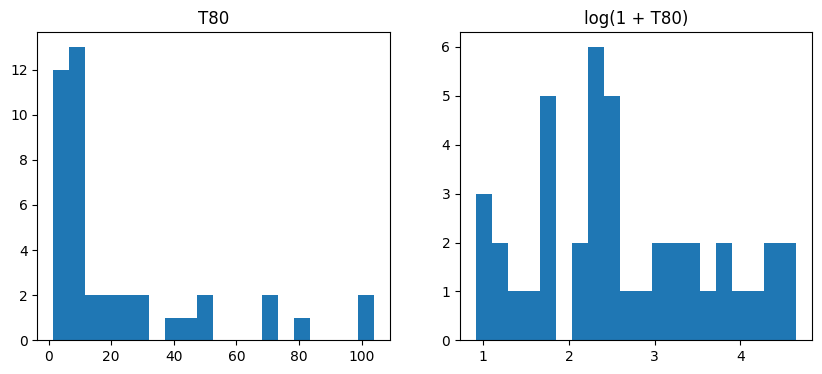

In [17]:
print(train["T80"].describe())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(train["T80"], bins=20)
ax[0].set_title("T80")

ax[1].hist(np.log1p(train["T80"]), bins=20)
ax[1].set_title("log(1 + T80)")
plt.show()

Section 2 — Explore the chemistry

Inspect the SMILES strings and visualize a few molecules using RDKit. Look at molecular mass, heteroatom count, and the provided features.

Output: a basic chemical understanding of the molecules.

In [18]:
!pip install rdkit

Failed to parse: 0


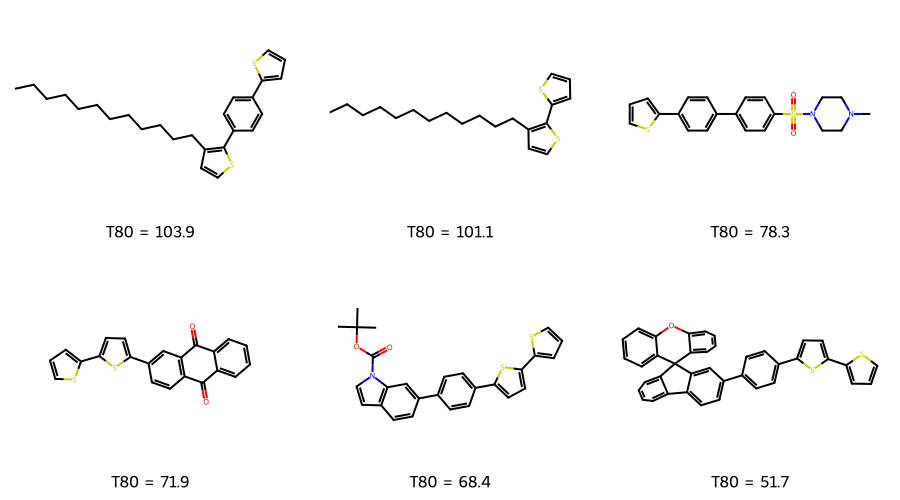

In [19]:
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors

smiles_col = "Smiles"
mols = [Chem.MolFromSmiles(s) for s in train[smiles_col]]
print("Failed to parse:", sum(m is None for m in mols))

# Draw the first 6 molecules with their T80 as a label
Draw.MolsToGridImage(
    mols[:6],
    molsPerRow=3,
    subImgSize=(300, 250),
    legends=[f"T80 = {t:.1f}" for t in train["T80"][:6]],
)

In [20]:
def count_heteroatoms(mol):
    return sum(1 for a in mol.GetAtoms() if a.GetAtomicNum() not in (1,6))

train["my_mass"] = [Descriptors.MolWt(m) for m in mols]
train["my_hetero"] = [count_heteroatoms(m) for m in mols]

print(train[["Mass", "my_mass", "NumHeteroatoms", "my_hetero"]].head(10))

      Mass  my_mass  NumHeteroatoms  my_hetero
0  410.692  410.692               2          2
1  334.594  334.594               2          2
2  398.553  398.553               6          6
3  372.470  372.470               4          4
4  457.620  457.620               5          5
5  572.754  572.754               3          3
6  425.575  425.575               6          6
7  374.494  374.494               6          6
8  580.975  580.975               5          5
9  522.735  522.735               4          4


In [21]:
print(list(train.columns))

['Batch_ID', 'T80', 'Smiles', 'Mass', 'HAcceptors', 'HDonors', 'LogP', 'Asphericity', 'Rg', 'TPSA', 'RingCount', 'NumRotatableBonds', 'NumHeteroatoms', 'HOMOm1(eV)', 'HOMO(eV)', 'LUMO(eV)', 'LUMOp1(eV)', 'PrimeState', 'PrimeExcite(eV)', 'PrimeExcite(osc)', 'DipoleMoment(Debye)', 'SurfaceCharge', 'ChargeCorrection', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15', 'T16', 'T17', 'T18', 'T19', 'T20', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'S19', 'S20', 'O1', 'O2', 'O3', 'O4', 'O5', 'O6', 'O7', 'O8', 'O9', 'O10', 'O11', 'O12', 'O13', 'O14', 'O15', 'O16', 'O17', 'O18', 'O19', 'O20', 'TDOS1.5', 'TDOS1.6', 'TDOS1.7', 'TDOS1.8', 'TDOS1.9', 'TDOS2.0', 'TDOS2.1', 'TDOS2.2', 'TDOS2.3', 'TDOS2.4', 'TDOS2.5', 'TDOS2.6', 'TDOS2.7', 'TDOS2.8', 'TDOS2.9', 'TDOS3.0', 'TDOS3.1', 'TDOS3.2', 'TDOS3.3', 'TDOS3.4', 'TDOS3.5', 'TDOS3.6', 'TDOS3.7', 'TDOS3.8', 'TDOS3.9', 'TDOS4.0', 'TDO

Section 3 — Explore the target and features

Plot T80 against a few features. Check whether higher molecular mass, more heteroatoms, or TDOS4.0 appear related to photostability.

Output: a few graphs and initial hypotheses.

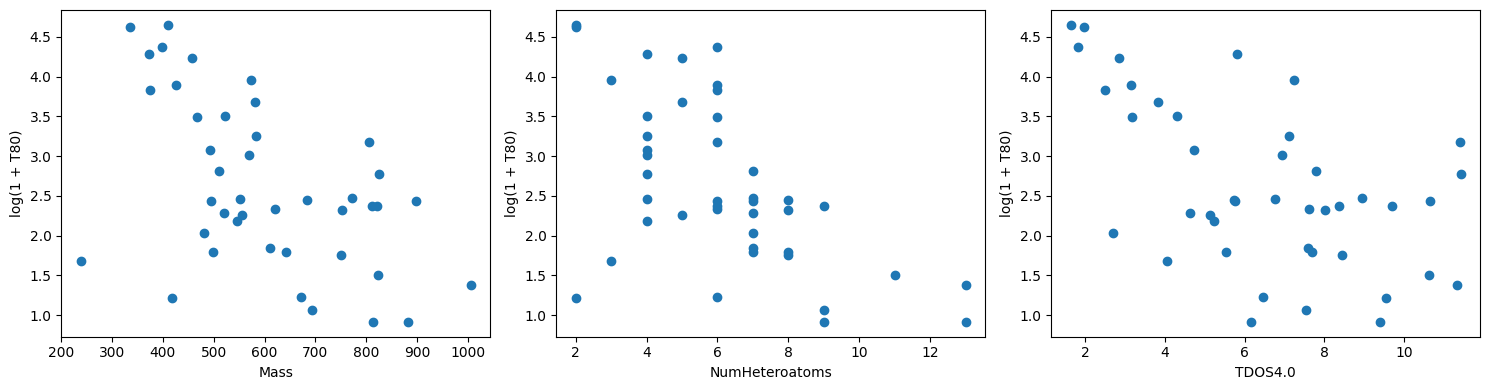

In [22]:
train["logT80"] = np.log1p(train["T80"])
key_feats = ["Mass", "NumHeteroatoms", "TDOS4.0"]

fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, f in zip(axes, key_feats):
    ax.scatter(train[f], train["logT80"])
    ax.set_xlabel(f)
    ax.set_ylabel("log(1 + T80)")
plt.tight_layout()
plt.show()

In [23]:
corr = train.corr(numeric_only=True)["logT80"].drop(["logT80", "T80"])
print(corr.abs().sort_values(ascending=False).head(10))

NumHeteroatoms    0.585401
my_hetero         0.585401
HAcceptors        0.574648
TDOS3.9           0.573560
TDOS4.0           0.556002
S15               0.536258
S12               0.534590
S17               0.534455
S16               0.531641
S14               0.529947
Name: logT80, dtype: float64


Section 4 : Build a baseline model

Start with a simple model, such as linear regression or Ridge regression, then compare it with a random forest.

Output: your first predictions and a baseline score.

In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor


drop_cols = ["Batch_ID", "Smiles", "T80", "logT80", "my_mass", "my_hetero"]
feature_cols = [c for c in train.columns
               if c not in drop_cols and pd.api.types.is_numeric_dtype(train[c])]
print(len(feature_cols), "features")

X = train[feature_cols]
y = train ["logT80"]

ridge = make_pipeline(SimpleImputer(strategy="median"),
                     StandardScaler(),
                     Ridge(alpha=10))
rf = make_pipeline(SimpleImputer(strategy="median"),
                  RandomForestRegressor(n_estimators=300, random_state=0))

ridge.fit(X, y)
rf.fit(X,y)

#Sanity Check
for name, model in [("ridge", ridge), ("rf", rf)]:
    pred = model.predict(X)
    print(name, "train RMSLE:", np.sqrt(np.mean((pred - y)** 2)))

143 features
ridge train RMSLE: 0.3359583672369729
rf train RMSLE: 0.3369790541693188


Section 5 : Validate and improve

Hold out some training molecules or use cross-validation. Compare models using the competition's metric, mean squared logarithmic error (MSLE).

Output: a fair comparison of models on unseen training examples.

In [25]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.dummy import DummyRegressor

In [26]:
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=0)

def msle_cv(model, X, y):
    scores = cross_val_score(model, X, y, cv = cv, scoring="neg_mean_squared_error")
    return -scores.mean(), scores.std()

models = {
    "mean baseline" : make_pipeline(SimpleImputer(), DummyRegressor()),
    "ridge a=1": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1)),
    "ridge a=10": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10)),
    "ridge a=100": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=100)),
        "rf":         make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=300, random_state=0)),
    "rf depth 4": make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=300, max_depth=4, random_state=0)),}

for name, m in models.items():
    msle, sd = msle_cv(m, X,y)
    print(f"{name:15s} MSLE = {msle:.4f} (+/- {sd:.4f}")

mean baseline   MSLE = 1.1326 (+/- 0.3147
ridge a=1       MSLE = 3.5781 (+/- 4.3130
ridge a=10      MSLE = 1.7666 (+/- 1.6194
ridge a=100     MSLE = 0.8627 (+/- 0.3922
rf              MSLE = 0.8278 (+/- 0.3204
rf depth 4      MSLE = 0.8275 (+/- 0.3202


In [27]:
top3 = ["TDOS4.0", "NumHeteroatoms", "Mass"]
small_ridge = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1))
small_rf = make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestRegressor(n_estimators=300, max_depth=4, random_state=0))

print("ridge, 3 features:", msle_cv(small_ridge, train[top3], y))
print("rf,    3 features:", msle_cv(small_rf, train[top3], y))

ridge, 3 features: (np.float64(0.6467380908147968), np.float64(0.22501022414108598))
rf,    3 features: (np.float64(0.745670000794973), np.float64(0.30935967140303944))


In [28]:
from sklearn.model_selection import LeaveOneOut, cross_val_predict

def loo_msle(model, X_data):
    p = cross_val_predict(model, X_data, y, cv=LeaveOneOut())
    return np.mean((p - y) ** 2)

print("mean baseline      :", round(loo_msle(make_pipeline(SimpleImputer(), DummyRegressor()), train[top3]), 3))
for a in [0.1, 1, 3, 10, 30, 100]:
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=a))
    print(f"ridge top3, alpha={a:>5}:", round(loo_msle(m, train[top3]), 3))

mean baseline      : 1.125
ridge top3, alpha=  0.1: 0.69
ridge top3, alpha=    1: 0.685
ridge top3, alpha=    3: 0.685
ridge top3, alpha=   10: 0.696
ridge top3, alpha=   30: 0.721
ridge top3, alpha=  100: 0.81


                       MSLE    Std  RMSLE  Improvement vs baseline (%)
ridge a=1 (3 feats)   0.647  0.225  0.804                       42.895
rf depth 4 (3 feats)  0.746  0.309  0.864                       34.160
rf depth 4 (all)      0.828  0.320  0.910                       26.934
rf (all)              0.828  0.320  0.910                       26.908
ridge a=100 (all)     0.863  0.392  0.929                       23.826
mean baseline         1.133  0.315  1.064                        0.000
ridge a=10 (all)      1.767  1.619  1.329                      -55.988
ridge a=1 (all)       3.578  4.313  1.892                     -215.930


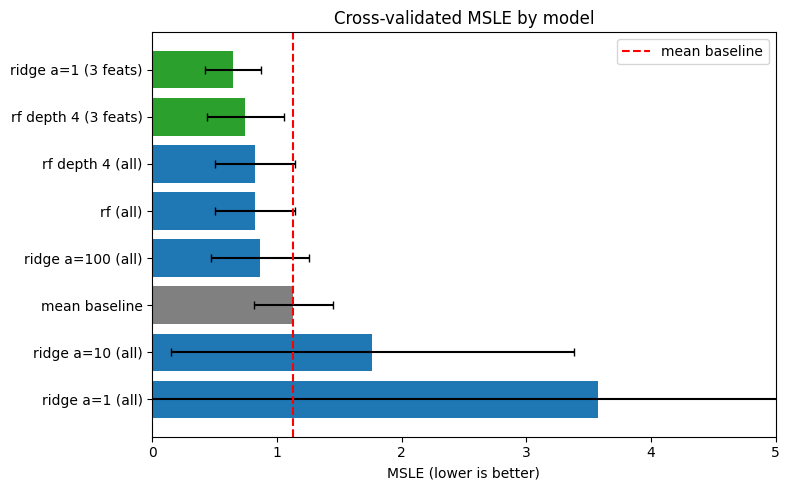

/tmp/ipykernel_49/1591171370.py:46: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([fold_scores[n] for n in order], labels=order, vert=True)


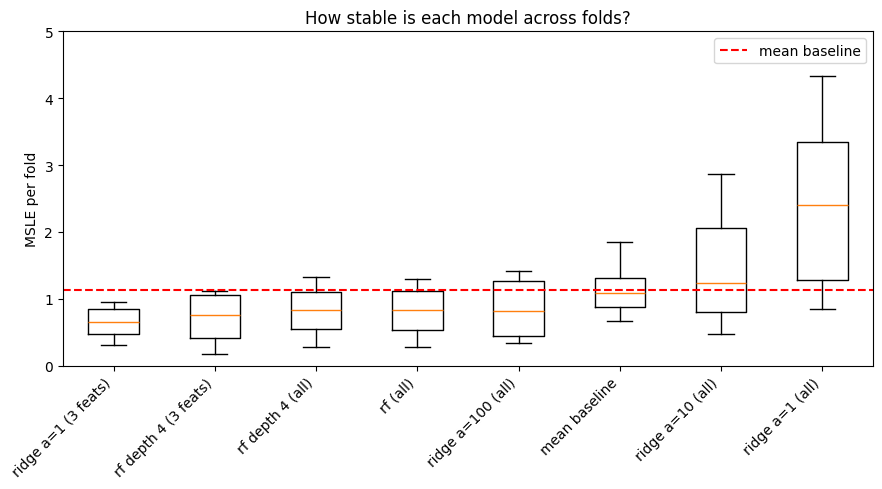

In [29]:
fold_scores = {}

def run(name, model, X_data):
    s = -cross_val_score(model, X_data, y, cv = cv, scoring="neg_mean_squared_error")
    fold_scores[name] = s

# All-feature models
for name, m in models.items():
    label = name if name == "mean baseline" else name + " (all)"
    run(label, m, X)

# 3-feature models
run("ridge a=1 (3 feats)", small_ridge, train[top3])
run("rf depth 4 (3 feats)", small_rf, train[top3])

# ---------- Table ----------
table = pd.DataFrame({
    "MSLE": {k: v.mean() for k, v in fold_scores.items()},
    "Std":  {k: v.std()  for k, v in fold_scores.items()},
})
table["RMSLE"] = np.sqrt(table["MSLE"])
base = table.loc["mean baseline", "MSLE"]
table["Improvement vs baseline (%)"] = (1 - table["MSLE"] / base) * 100
table = table.sort_values("MSLE")
print(table.round(3))

# ---------- Plot 1: average MSLE with error bars ----------
colors = ["gray" if n == "mean baseline"
          else "tab:green" if "3 feats" in n
          else "tab:blue" for n in table.index]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(table.index, table["MSLE"], xerr=table["Std"], color=colors, capsize=3)
ax.axvline(base, color="red", linestyle="--", label="mean baseline")
ax.set_xlim(0, 5)                      # ridge a=1 is huge; this keeps the plot readable
ax.set_xlabel("MSLE (lower is better)")
ax.set_title("Cross-validated MSLE by model")
ax.invert_yaxis()                      # best model at the top
ax.legend()
plt.tight_layout()
plt.show()

# ---------- Plot 2: spread of the 15 fold scores ----------
order = list(table.index)
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([fold_scores[n] for n in order], labels=order, vert=True)
ax.axhline(base, color="red", linestyle="--", label="mean baseline")
ax.set_ylim(0, 5)
ax.set_ylabel("MSLE per fold")
ax.set_title("How stable is each model across folds?")
plt.xticks(rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

Section 6 : Identify important molecular features

Examine which features your best model uses. Check whether the competition's known candidates—TDOS4.0, NumHeteroatoms, and Mass—are useful in your model.

Output: a small, interpretable set of potentially important features.

In [30]:
from itertools import combinations
from sklearn.linear_model import Ridge, Lasso, LassoCV
from sklearn.model_selection import RepeatedKFold, KFold, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import SelectKBest, f_regression

top3 = ["TDOS4.0", "NumHeteroatoms", "Mass"]
# X, y, train, test, cv and msle_cv must already exist from the earlier sections
print(X.shape, y.shape, test.shape)

(42, 143) (42,) (9, 146)


6A: Random Forest Importance

TDOS3.9                0.104
TDOS3.8                0.074
Mass                   0.058
TDOS4.0                0.050
TDOS2.9                0.043
NumHeteroatoms         0.038
DipoleMoment(Debye)    0.036
S3                     0.034
TDOS3.0                0.027
LUMO(eV)               0.024
HOMOm1(eV)             0.021
SDOS4.0                0.020
S5                     0.020
S2                     0.019
TDOS4.1                0.019
dtype: float64


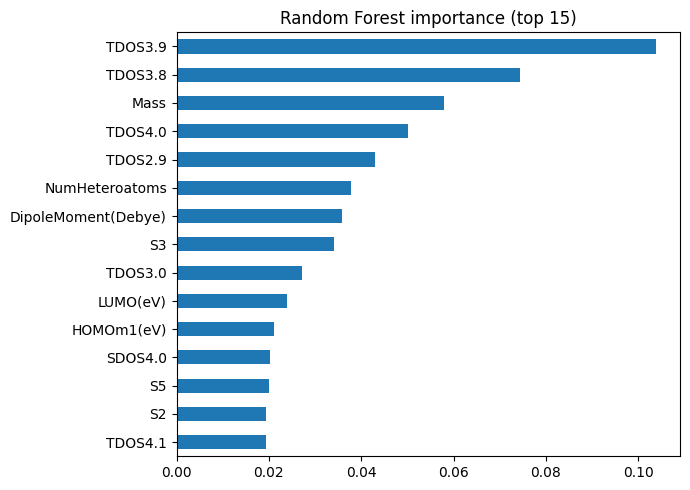

TDOS4.0          RF rank: 4 of 143
NumHeteroatoms   RF rank: 6 of 143
Mass             RF rank: 3 of 143


In [31]:
rf_best = make_pipeline(SimpleImputer(strategy="median"),
                        RandomForestRegressor(n_estimators=500, max_depth=4, random_state=0))
rf_best.fit(X, y)

rf_imp = pd.Series(rf_best[-1].feature_importances_, index=X.columns).sort_values(ascending=False)
print(rf_imp.head(15).round(3))

rf_imp.head(15)[::-1].plot(kind="barh", figsize=(7, 5), title="Random Forest importance (top 15)")
plt.tight_layout(); plt.show()

for f in top3:
    print(f"{f:16s} RF rank: {rf_imp.index.get_loc(f) + 1} of {len(rf_imp)}")

6B: Permutation importance on held-out molecules

In [32]:
kf = KFold(n_splits=5, shuffle=True, random_state=0)
perm_all = []

for tr_idx, va_idx in kf.split(X):
    m = make_pipeline(SimpleImputer(strategy="median"),
                      RandomForestRegressor(n_estimators=200, max_depth=4, random_state=0))
    m.fit(X.iloc[tr_idx], y.iloc[tr_idx])
    r = permutation_importance(m, X.iloc[va_idx], y.iloc[va_idx],
                               n_repeats=10, random_state=0,
                               scoring="neg_mean_squared_error")
    perm_all.append(r.importances_mean)

perm_imp = pd.Series(np.mean(perm_all, axis=0), index=X.columns).sort_values(ascending=False)
print(perm_imp.head(15).round(4))

for f in top3:
    print(f"{f:16s} permutation rank: {perm_imp.index.get_loc(f) + 1} of {len(perm_imp)}")

TDOS4.0           0.0337
TDOS3.9           0.0312
Mass              0.0284
TDOS2.9           0.0251
NumHeteroatoms    0.0148
S5                0.0092
HAcceptors        0.0089
TDOS3.0           0.0088
SDOS4.0           0.0083
TPSA              0.0083
O2                0.0079
TDOS4.1           0.0077
SurfaceCharge     0.0073
TDOS3.2           0.0058
TDOS3.3           0.0056
dtype: float64
TDOS4.0          permutation rank: 1 of 143
NumHeteroatoms   permutation rank: 5 of 143
Mass             permutation rank: 3 of 143


6C: Lasso and bootstrap stability

In [33]:
# Prepare data: fill missing values, then put all features on the same scale
Xs = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X))

# Let cross-validation choose how strong the penalty should be
lasso_cv = LassoCV(cv=5, random_state=0, max_iter=50000).fit(Xs, y)
print("chosen alpha:", lasso_cv.alpha_)
coefs = pd.Series(lasso_cv.coef_, index=X.columns)
print("Non-zero coefficients:\n", coefs[coefs != 0].sort_values(key=abs, ascending=False).round(3))

# Stability: refit on 100 resampled datasets and count how often each feature survives
counts = pd.Series(0, index=X.columns, dtype=float)
n_boot = 100
for seed in range(n_boot):
    idx = np.random.default_rng(seed).choice(len(y), size=len(y), replace=True)
    l = Lasso(alpha=lasso_cv.alpha_, max_iter=50000).fit(Xs[idx], y.iloc[idx])
    counts += (l.coef_ != 0)

lasso_freq = (counts / n_boot).sort_values(ascending=False)
print(lasso_freq.head(15).round(2))

chosen alpha: 0.0987981867333013
Non-zero coefficients:
 TDOS4.0             -0.320
NumHeteroatoms      -0.304
T1                   0.172
TDOS3.3              0.155
TDOS4.6              0.133
O14                 -0.119
O10                  0.070
TDOS2.8             -0.061
HDonors             -0.034
NumRotatableBonds   -0.020
T5                   0.007
dtype: float64
NumHeteroatoms       0.62
NumRotatableBonds    0.56
O10                  0.56
TDOS4.0              0.49
O14                  0.45
T1                   0.40
TDOS3.3              0.38
TDOS4.6              0.34
O18                  0.34
HDonors              0.34
TDOS3.9              0.32
TDOS4.5              0.31
O11                  0.29
O19                  0.28
TDOS3.2              0.27
dtype: float64


6D: Combine the three rankings

In [34]:
ranks = pd.DataFrame({
    "RF":          rf_imp.rank(ascending=False),
    "Permutation": perm_imp.rank(ascending=False),
    "Lasso freq":  lasso_freq.rank(ascending=False),
})
ranks["avg_rank"] = ranks.mean(axis=1)
ranks = ranks.sort_values("avg_rank")

print(ranks.head(15).round(1))
print("\nYour three known features:")
print(ranks.loc[top3].round(1))

                     RF  Permutation  Lasso freq  avg_rank
TDOS4.0             4.0          1.0         4.0       3.0
NumHeteroatoms      6.0          5.0         1.0       4.0
TDOS3.9             1.0          2.0        11.0       4.7
TDOS2.9             5.0          4.0        19.5       9.5
Mass                3.0          3.0        29.0      11.7
TDOS3.3            17.0         15.0         7.0      13.0
HAcceptors         16.0          7.0        21.0      14.7
NumRotatableBonds  29.0         17.0         2.5      16.2
T5                 18.0         19.0        17.5      18.2
TDOS3.2            27.0         14.0        15.5      18.8
LUMO(eV)           10.0         23.0        26.0      19.7
O16                24.0         26.0        15.5      21.8
S6                 22.0         16.0        30.5      22.8
TPSA               26.0         10.0        35.0      23.7
SDOS4.0            12.0          9.0        53.5      24.8

Your three known features:
                 RF  Permuta

6E: Test small feature sets honestly

TDOS4.0 + NumHeteroatoms + Mass    0.647
TDOS4.0 + NumHeteroatoms           0.655
NumHeteroatoms + Mass              0.751
NumHeteroatoms                     0.764
TDOS4.0                            0.827
TDOS4.0 + Mass                     0.841
Mass                               0.852
dtype: float64


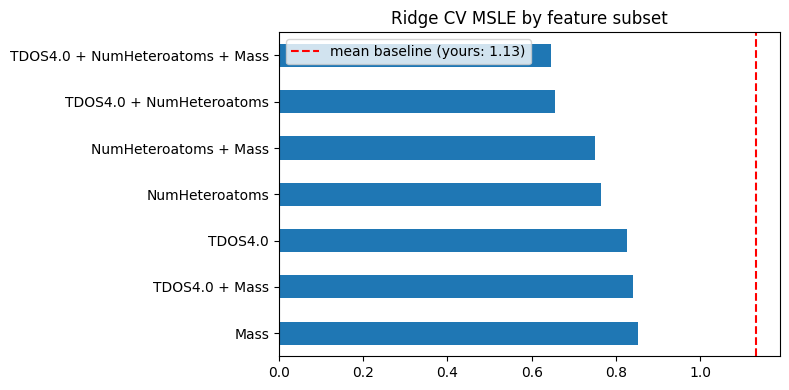

In [35]:
subset_scores = {}
for r in (1, 2, 3):
    for combo in combinations(top3, r):
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1))
        mean_msle, sd = msle_cv(m, train[list(combo)], y)
        subset_scores[" + ".join(combo)] = mean_msle

subset_scores = pd.Series(subset_scores).sort_values()
print(subset_scores.round(3))

subset_scores[::-1].plot(kind="barh", figsize=(8, 4), title="Ridge CV MSLE by feature subset")
plt.axvline(base, color="red", linestyle="--", label="mean baseline ({base:.2f})")
plt.legend(); plt.tight_layout(); plt.show()

In [36]:
alphas = [0.01, 0.1, 1, 3, 10, 30, 100]
alpha_scores = {}
for a in alphas:
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=a))
    alpha_scores[a] = msle_cv(m, train[top3], y)[0]
alpha_scores = pd.Series(alpha_scores)
print(alpha_scores.round(3))
best_alpha = alpha_scores.idxmin()
print("best alpha:", best_alpha)

0.01      0.650
0.10      0.649
1.00      0.647
3.00      0.652
10.00     0.672
30.00     0.713
100.00    0.827
dtype: float64
best alpha: 1.0


In [37]:
for k in [1, 2, 3, 5, 10, 20]:
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      SelectKBest(f_regression, k=k), Ridge(alpha=10))
    print(f"top {k:2d} chosen automatically inside CV: MSLE = {msle_cv(m, X, y)[0]:.3f}")

top  1 chosen automatically inside CV: MSLE = 1.065
top  2 chosen automatically inside CV: MSLE = 1.086
top  3 chosen automatically inside CV: MSLE = 1.068
top  5 chosen automatically inside CV: MSLE = 0.988
top 10 chosen automatically inside CV: MSLE = 0.929
top 20 chosen automatically inside CV: MSLE = 0.928


6F: brute-force small subsets

In [38]:
shortlist = list(ranks.head(15).index)   # top 15 by average rank
results = []
for r in (1, 2, 3):
    for combo in combinations(shortlist, r):
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1))
        results.append((msle_cv(m, train[list(combo)], y)[0], combo))

for score, combo in sorted(results)[:10]:
    print(round(score, 3), combo)

0.603 ('TDOS4.0', 'NumHeteroatoms', 'TDOS3.2')
0.604 ('NumHeteroatoms', 'TDOS3.9', 'TDOS3.2')
0.606 ('TDOS4.0', 'NumHeteroatoms', 'TDOS3.3')
0.611 ('NumHeteroatoms', 'TDOS3.9', 'TDOS3.3')
0.635 ('TDOS3.9', 'HAcceptors', 'TDOS3.2')
0.641 ('TDOS4.0', 'HAcceptors', 'TDOS3.2')
0.642 ('NumHeteroatoms', 'TDOS3.3', 'S6')
0.644 ('NumHeteroatoms', 'TDOS3.2', 'S6')
0.645 ('TDOS3.9', 'TDOS3.3', 'HAcceptors')
0.646 ('TDOS4.0', 'TDOS3.3', 'HAcceptors')


Section 7 : Generate the submission

Train your chosen model on all labeled training molecules, predict T80 for the test molecules, and save the predictions in the required CSV format.

Output: submission.csv containing ID and T80.

In [39]:
check = pd.DataFrame({
    "train_min": train[top3].min(),
    "train_max": train[top3].max(),
    "test_min":  test[top3].min(),
    "test_max":  test[top3].max(),
    "test_missing": test[top3].isna().sum(),
})
print(check.round(2))

for f in top3:
    outside = ((test[f] < train[f].min()) | (test[f] > train[f].max())).sum()
    print(f"{f}: {outside} test molecules outside the training range")

                train_min  train_max  test_min  test_max  test_missing
TDOS4.0              1.63      11.42      2.28      5.12             0
NumHeteroatoms       2.00      13.00      2.00      5.00             0
Mass               238.32    1005.43    238.32    500.88             0
TDOS4.0: 0 test molecules outside the training range
NumHeteroatoms: 0 test molecules outside the training range
Mass: 0 test molecules outside the training range


7B: Fit the final models

In [40]:
# Use best_alpha from Section 6E (or set your own, e.g. 1)
final_ridge = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                            Ridge(alpha=best_alpha))
final_rf = make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestRegressor(n_estimators=500, max_depth=4, random_state=0))

final_ridge.fit(train[top3], y)
final_rf.fit(train[top3], y)

# What did the linear model learn? (coefficients are per standardized feature)
coef = pd.Series(final_ridge[-1].coef_, index=top3)
print(coef.round(3))

TDOS4.0          -0.566
NumHeteroatoms   -0.569
Mass              0.277
dtype: float64


7C: Predict and compare the models

In [41]:
pred_ridge_log = final_ridge.predict(test[top3])
pred_rf_log    = final_rf.predict(test[top3])

# Blend: 70% ridge, 30% forest (ridge validated better in your CV)
pred_log = 0.7 * pred_ridge_log + 0.3 * pred_rf_log

compare = pd.DataFrame({
    "Batch_ID": test["Batch_ID"],
    "ridge_T80": np.expm1(pred_ridge_log),
    "rf_T80":    np.expm1(pred_rf_log),
    "blend_T80": np.expm1(pred_log),
})
print(compare.round(2))
print("Training T80 range:", train["T80"].min(), "to", train["T80"].max())

  Batch_ID  ridge_T80  rf_T80  blend_T80
0  Test-01      30.59   48.46      35.14
1  Test-02      30.60   31.25      30.80
2  Test-03      17.84   24.62      19.66
3  Test-04      28.41   21.87      26.27
4  Test-05      41.74   31.69      38.44
5  Test-06      37.64   32.77      36.11
6  Test-07      24.15   54.27      30.85
7  Test-08      24.62   12.95      20.35
8  Test-09      25.70   16.65      22.59
Training T80 range: 1.5 to 103.86


7D: Build and verify the file

In [42]:
pred = np.clip(np.expm1(pred_log), 0, None)

sample = pd.read_csv(glob.glob("/kaggle/input/**/sample_submission.csv", recursive=True)[0])
print(sample.head())
id_sub = sample.columns[0]

pred_by_id = pd.Series(pred, index=test["Batch_ID"].values)
assert set(sample[id_sub]) == set(pred_by_id.index), "IDs differ between sample and test"

sample["T80"] = pred_by_id.reindex(sample[id_sub]).values
assert sample["T80"].notna().all() and (sample["T80"] >= 0).all()
sample.to_csv("submission.csv", index=False)
print("Saved:", sample.shape)
print(pd.read_csv("submission.csv"))

  Batch_ID  T80
0  Test-01  1.5
1  Test-02  2.5
2  Test-03  3.5
3  Test-04  4.5
4  Test-05  5.5
Saved: (9, 2)
  Batch_ID        T80
0  Test-01  35.142331
1  Test-02  30.796000
2  Test-03  19.656898
3  Test-04  26.269771
4  Test-05  38.435665
5  Test-06  36.108832
6  Test-07  30.853681
7  Test-08  20.350041
8  Test-09  22.585460


7E: Plot where your predictions fall

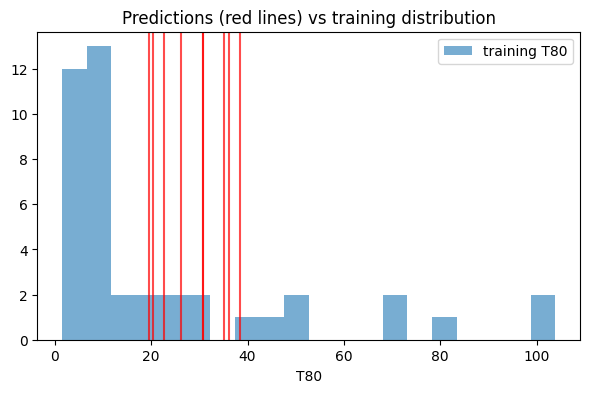

In [43]:
plt.figure(figsize=(7, 4))
plt.hist(train["T80"], bins=20, alpha=0.6, label="training T80")
for p in pred:
    plt.axvline(p, color="red", alpha=0.7)
plt.xlabel("T80"); plt.title("Predictions (red lines) vs training distribution")
plt.legend(); plt.show()

Section 8: Symbolic Regression

In [44]:
!pip install gplearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 56.5 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


In [45]:
from gplearn.genetic import SymbolicRegressor

sr_features = top3          # or the top 4-5 features from your Section 6 ranking

sr_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SymbolicRegressor(population_size=1000, generations=15,
                      function_set=("add", "sub", "mul", "div"),
                      parsimony_coefficient=0.05,   # larger = simpler formulas
                      random_state=0, n_jobs=1)
)

# Honest comparison with Ridge, using the same CV (this can take a few minutes)
sr_score = msle_cv(sr_model, train[sr_features], y)
print("Symbolic regression CV MSLE:", sr_score)
print("Ridge (3 features) CV MSLE:  ", msle_cv(final_ridge, train[top3], y))

# Fit on all data and print the formula it found
sr_model.fit(train[sr_features], y)
print(sr_model[-1]._program)

Symbolic regression CV MSLE: (np.float64(1.2522585170636578), np.float64(0.3692659011288788))
Ridge (3 features) CV MSLE:   (np.float64(0.6467380908147968), np.float64(0.22501022414108598))
add(sub(0.900, X1), sub(0.900, -0.854))


Validating the blend

In [46]:
Xt = train[top3]; yv = y.values
p_r, p_f = np.zeros(len(yv)), np.zeros(len(yv))
for tr, va in LeaveOneOut().split(Xt):
    r = make_pipeline(StandardScaler(), Ridge(alpha=1)).fit(Xt.iloc[tr], yv[tr])
    f = RandomForestRegressor(n_estimators=300, max_depth=4, random_state=0).fit(Xt.iloc[tr], yv[tr])
    p_r[va], p_f[va] = r.predict(Xt.iloc[va]), f.predict(Xt.iloc[va])
for name, p in [("ridge", p_r), ("rf", p_f), ("blend 70/30", 0.7*p_r + 0.3*p_f)]:
    print(name, round(np.mean((p - yv) ** 2), 3))

ridge 0.685
rf 0.828
blend 70/30 0.68
